# Greedy + Simulated Annealing for Capacitated Facility Location
**MSc Optimization Methods — Member B**

## 1. Introduction
The Capacitated Facility Location Problem (CFLP) asks where to open warehouses and which warehouse should serve each customer city. We minimize opening plus transport costs while respecting capacities.

The instances come from the **Olist Brazilian E-Commerce dataset**. Demand represents delivered orders aggregated by city and state. Candidate warehouses are selected from large-demand cities. Opening costs and capacities are modelling assumptions constructed by preprocessing, rather than observed warehouse records. Costs are model cost units, not claimed real currency expenditure.

**Member A:** exact MILP and CBC solution. **Member B:** feasible Greedy initialization, Simulated Annealing (SA), testing, experiments and interpretation. This notebook imports the existing algorithms rather than redefining them.

**Presentation route:** setup → formulation → algorithms → one small demonstration → saved experiment tables and figures → discussion. The full experiment rerun is optional and disabled.

### Setup: local Jupyter or a fresh Google Colab runtime
All code works from the **repository root** using relative paths.

**Local VS Code Jupyter or Jupyter:** select a Python kernel with the project display dependencies, open this notebook inside the existing repository and run cells top to bottom. Root discovery supports starting in the repository root or `notebooks/`. Local execution never imports Google Colab modules, requests ZIP uploads, or clones the repository. It reads instances from `data/processed/` and saved results from `data/` after changing to the repository root. If the root cannot be found, setup stops with a local path instruction.

**Automatic detection:** setup checks whether `google.colab` is already loaded or Colab runtime environment markers are present; it does not import Colab just to detect the environment. In Colab, an existing project is reused; otherwise the secure ZIP-upload workflow below is offered.

**Fresh Colab / private repository — ZIP-upload workflow:**

1. Open this notebook in Colab through **File → Upload notebook**.
2. Prepare a ZIP of the current project folder containing `scripts/`, `data/processed/`, saved MILP/heuristic results and figures, and `notebooks/`. Include all uncommitted Member B files. Exclude `.git/`, virtual environments, raw data and credential files.
3. Run the setup cell and select that ZIP when prompted. It extracts the archive and selects the root.
4. Continue with **Runtime → Run all**. CPU is sufficient; no GPU is required.

For a private GitHub repository, download a branch ZIP in your authenticated browser session. Do not paste tokens into cells or URLs. **A GitHub ZIP works only if it already contains the Member B files:** the current uncommitted scripts and results must be included in your working-folder ZIP. No credentials are hardcoded, and this notebook does not commit or push.

In [1]:
from pathlib import Path
import os
import sys
import tempfile
import zipfile

sys.dont_write_bytecode = True
os.environ["PYTHONDONTWRITEBYTECODE"] = "1"

REQUIRED_FILES = [
    "scripts/cflp_common.py", "scripts/heuristic.py",
    "scripts/run_heuristic_experiments.py", "scripts/compare_methods.py",
    "data/processed/cflp_n20_m10.json", "data/processed/cflp_n50_m15.json",
    "data/processed/cflp_n100_m25.json", "data/processed/cflp_n200_m40.json",
    "data/milp_results.csv", "data/heuristic_results.csv",
    "data/heuristic_solutions.json", "data/sa_convergence.csv",
    "data/heuristic_comparison.csv", "data/heuristic_plots.png",
    "data/heuristic_convergence.png",
]

def find_repository(start):
    start = Path(start).resolve()
    candidates = [start, *start.parents]
    candidates += [path.parent.parent for path in start.glob("*/scripts/cflp_common.py")]
    for candidate in candidates:
        if (candidate / "scripts/cflp_common.py").is_file():
            return candidate
    return None

# Detect Colab without importing its modules in local VS Code/Jupyter.
IN_COLAB = ("google.colab" in sys.modules
            or bool(os.environ.get("COLAB_RELEASE_TAG"))
            or bool(os.environ.get("COLAB_BACKEND_VERSION")))

ROOT = find_repository(Path.cwd())
if ROOT is None and not IN_COLAB:
    raise FileNotFoundError(
        "Local repository root not found. Open VS Code/Jupyter in the existing "
        "repository or its notebooks/ directory. No upload or clone is attempted."
    )
if ROOT is None and IN_COLAB:
    from google.colab import files
    print("Upload one project ZIP containing scripts and saved results.")
    uploaded = files.upload()
    archives = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(archives) != 1:
        raise ValueError("Upload exactly one project ZIP.")
    extraction_dir = Path(tempfile.mkdtemp(prefix="cflp_upload_", dir=Path.cwd()))
    with zipfile.ZipFile(archives[0]) as archive:
        for member in archive.infolist():
            destination = (extraction_dir / member.filename.replace("\\", "/")).resolve()
            if not destination.is_relative_to(extraction_dir.resolve()):
                raise ValueError("ZIP contains a path outside the extraction folder.")
        archive.extractall(extraction_dir)
    ROOT = find_repository(extraction_dir)
    if ROOT is None:
        raise FileNotFoundError("ZIP must contain scripts/cflp_common.py at its root or one project-folder level below.")

missing_files = [name for name in REQUIRED_FILES if not (ROOT / name).is_file()]
if missing_files:
    raise FileNotFoundError("Project is incomplete. Missing files: " + ", ".join(missing_files))
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Environment:", "Google Colab" if IN_COLAB else "Local Jupyter / VS Code")
print("Working from repository root; all required source, instance and result files are present.")

Environment: Local Jupyter / VS Code
Working from repository root; all required source, instance and result files are present.


In [2]:
import importlib.util
import subprocess

# Colab normally includes these. Install display dependencies only if missing.
missing_packages = [name for name in ("pandas", "matplotlib")
                    if importlib.util.find_spec(name) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])

import json
import hashlib
import math
import pandas as pd
from IPython.display import display, Markdown, Image

from scripts.cflp_common import load_instance, evaluate
from scripts.heuristic import greedy_initial_solution, simulated_annealing
from scripts.run_heuristic_experiments import run_experiments, SEEDS, write_csv
from scripts.compare_methods import (
    read_csv, compare_results, print_comparison, create_plots, COMPARISON_FIELDS,
)
print("All four existing modules imported; no algorithms reimplemented.")
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__)

All four existing modules imported; no algorithms reimplemented.
Python: 3.14.5 | pandas: 3.0.6


## 2. Mathematical formulation
Let $i=1,\ldots,m$ index candidate warehouses and $j=1,\ldots,n$ customer cities.

- $y_i\in\{0,1\}$: warehouse $i$ is open.
- $x_{ij}\in\{0,1\}$: customer $j$ is assigned to warehouse $i$.
- $f_i$: fixed opening cost; $c_{ij}$: full assignment cost; $d_j$: demand; $C_i$: capacity.

$$\min\;\sum_i f_i y_i+\sum_i\sum_j c_{ij}x_{ij}$$

subject to
$$\sum_i x_{ij}=1\quad\forall j,$$
$$x_{ij}\le y_i\quad\forall i,j,$$
$$\sum_j d_jx_{ij}\le C_i y_i\quad\forall i.$$

The first constraint enforces **single-source assignment**: a city's whole demand goes to one warehouse; splitting is forbidden.

The heuristic uses `solution[j] = i` and infers openings from used facilities, charging each once. Unused open warehouses are not represented; with the positive opening costs in these instances, they provide no benefit.

**Matrix orientation:** `assign_cost[i][j]` means facility row $i$, customer column $j$. It already includes demand: **do not multiply by demand again**. Stored costs are evaluated without internal rounding.

## 3. Greedy initialization
Customers are processed in descending demand order, with customer index breaking ties. Among facilities with sufficient residual capacity, choose the minimum incremental cost:

$$c_{ij}+\begin{cases}f_i,&\text{if facility }i\text{ is unused},\\0,&\text{otherwise.}\end{cases}$$

Facility index breaks cost ties. Larger cities are harder to fit into the remaining capacity, so placing them first reduces the risk of leaving enough total space but no warehouse able to fit a large city.

~~~text
Initialize zero loads and no used warehouses
For customer j in descending demand order:
    Find i with load[i] + demand[j] <= capacity[i]
    If none exist: report construction failure
    Choose minimum assignment cost + incremental opening cost
    Assign whole customer j to i; update load and used facilities
Validate complete assignment; return only if feasible
~~~

Total capacity and maximum-demand checks detect some impossible configurations. They do not prove single-source feasibility. **Greedy failure does not prove instance infeasibility.** The current implementation fails explicitly rather than using randomized restarts or exact repair.

## 4. Simulated Annealing
SA starts from feasible Greedy and uses a dedicated `random.Random(seed)`. It uniformly samples five neighborhood types:

| Operator | Attempt |
|---|---|
| Reassignment | Move one whole customer to another warehouse |
| Customer swap | Exchange two customers' assigned warehouses |
| Facility open | Transfer a customer to an unused warehouse |
| Facility close | Relocate every customer of a used warehouse to other used sites |
| Facility swap | Replace a used site with an unused site and redistribute customers |

Close/swap relocation uses demand-descending Greedy redistribution. Candidates are separate lists. **Every accepted candidate is complete and capacity-feasible.** Failed, unchanged or infeasible attempts consume an iteration and cooling step.

For $\Delta=\operatorname{cost}(s')-\operatorname{cost}(s)$:
$$P(\text{accept})=\begin{cases}1,&\Delta\le0,\\\exp(-\Delta/T),&\Delta>0.\end{cases}$$

The code uses an equivalent log-domain test for numerical safety. Accepting a worse current solution can help escape local minima. The **best solution is stored separately** and returned.

$$T_0=\max(1,0.01\times\text{Greedy cost}),\qquad
T\leftarrow\max(0.995T,10^{-300}).$$

Stopping condition: **2,000 attempted iterations**, not a wall-clock limit. History includes iteration 0, temperature, current cost and best cost. SA does not guarantee a global optimum.

## 5. Dataset loading
Load the four existing JSON instances without preprocessing or modifying data. Demand is delivered orders aggregated by city and state. Capacity and opening costs are constructed model parameters.

The capacity-only minimum $\lceil\sum_jd_j/\max_iC_i\rceil$ is a lower bound on openings, **not** a feasibility proof.

In [3]:
instance_paths = sorted(Path("data/processed").glob("cflp_*.json"))
instances = {data["name"]: data for data in map(load_instance, instance_paths)}
instances = dict(sorted(instances.items(), key=lambda item: item[1]["n_customers"]))
statistics_rows = []
for name, data in instances.items():
    demands = [c["demand"] for c in data["customers"]]
    capacities = [f["capacity"] for f in data["facilities"]]
    fixed = [f["fixed_cost"] for f in data["facilities"]]
    statistics_rows.append({
        "Instance": name, "Customers": data["n_customers"], "Sites": data["n_facilities"],
        "Total demand": sum(demands), "Largest demand": max(demands),
        "Min capacity": min(capacities), "Max capacity": max(capacities),
        "Total capacity": sum(capacities),
        "Capacity-only minimum open": math.ceil(sum(demands) / max(capacities)),
        "Min fixed cost": min(fixed), "Max fixed cost": max(fixed),
    })
display(pd.DataFrame(statistics_rows).round(2))
costs = instances["cflp_n20_m10"]["assign_cost"]
print("n20_m10 matrix:", len(costs), "facility rows ×", len(costs[0]), "customer columns")

,Instance,Customers,Sites,Total demand,Largest demand,Min capacity,Max capacity,Total capacity,Capacity-only minimum open,Min fixed cost,Max fixed cost
0,cflp_n20_m10,20,10,40455,15043,15043,15043,150430,3,1027791.66,1605924.47
1,cflp_n50_m15,50,15,50688,15043,15207,15207,228105,4,942761.42,1504406.52
2,cflp_n100_m25,100,25,60004,15043,18002,18002,450050,4,738463.27,1183434.73
3,cflp_n200_m40,200,40,69411,15043,20824,20824,832960,4,538385.18,882598.66


n20_m10 matrix: 10 facility rows × 20 customer columns


## 6. Small live demonstration
Run **one** 20-customer example with seed **42**. This is separate from the saved 40-run batch, whose seeds are 0–9. The demonstration does not alter saved outputs or enter the reported experiment statistics.

With identical code, parameters and environment, assignments and costs are reproducible. Runtime varies by machine and workload.

In [4]:
demo_instance = instances["cflp_n20_m10"]
greedy_solution = greedy_initial_solution(demo_instance)
greedy_cost, greedy_feasible = evaluate(greedy_solution, demo_instance)
assert greedy_feasible
demo = simulated_annealing(demo_instance, initial_solution=greedy_solution,
                           seed=42, iterations=2000, cooling_rate=0.995,
                           initial_temperature=None)
sa_cost, sa_feasible = evaluate(demo["solution"], demo_instance)
assert sa_feasible and len(demo["solution"]) == demo_instance["n_customers"]
assert sa_cost <= greedy_cost
display(pd.DataFrame([
    {"Method": "Greedy", "Cost": greedy_cost, "Feasible": greedy_feasible,
     "Open warehouses": len(set(greedy_solution))},
    {"Method": "SA (seed 42)", "Cost": sa_cost, "Feasible": sa_feasible,
     "Open warehouses": len(set(demo["solution"]))},
]).round(2))
print(f"Improvement over Greedy: {100 * (greedy_cost - sa_cost) / greedy_cost:.2f}%")
print(f"SA function runtime (Greedy supplied): {demo['runtime_s']:.3f} s")
print("Complete single-source assignment:", demo["solution"])

,Method,Cost,Feasible,Open warehouses
0,Greedy,14439731.09,True,5
1,SA (seed 42),10831298.05,True,5


Improvement over Greedy: 24.99%
SA function runtime (Greedy supplied): 5.801 s
Complete single-source assignment: [8, 1, 1, 3, 9, 9, 9, 7, 9, 9, 1, 9, 9, 9, 9, 3, 7, 9, 7, 9]


In [5]:
warehouse_rows = []
for i in sorted(set(demo["solution"])):
    facility = demo_instance["facilities"][i]
    served = [j for j, assigned in enumerate(demo["solution"]) if assigned == i]
    load = sum(demo_instance["customers"][j]["demand"] for j in served)
    warehouse_rows.append({"Warehouse": i, "City": facility["city"], "State": facility["state"],
                           "Customers served": len(served), "Load": load,
                           "Capacity": facility["capacity"], "Within capacity": load <= facility["capacity"]})
display(pd.DataFrame(warehouse_rows))

,Warehouse,City,State,Customers served,Load,Capacity,Within capacity
0,1,rio de janeiro,RJ,3,10123,15043,True
1,3,brasilia,DF,2,2568,15043,True
2,7,salvador,BA,3,2396,15043,True
3,8,guarulhos,SP,1,15043,15043,True
4,9,sao bernardo do campo,SP,11,10325,15043,True


## 7. Experiment configuration
Four instances × ten seeds = **40 runs**. Each run starts from newly constructed feasible Greedy. Greedy is deterministic, so its cost is unchanged across seeds; SA exploration varies.

| Parameter | Value |
|---|---|
| Seeds | 0–9 |
| SA attempts per run | 2,000 |
| Cooling rate | 0.995 |
| Initial temperature | max(1, 0.01 × Greedy cost) |
| Neighborhood choice | Uniform among five operators |
| Stopping | Fixed iteration budget |
| Internal rounding | None |

Times separate Greedy initialization and SA search. Their sum excludes input loading, final audit and file I/O. MILP time is solver time only. Saved timings are not a new controlled, same-runtime benchmark.

The solution JSON records full assignments, source/data SHA-256 hashes, Python and platform. Python-version differences can affect reproducibility.

In [6]:
saved_payload = json.loads(Path("data/heuristic_solutions.json").read_text(encoding="utf-8"))
metadata = saved_payload["metadata"]
display(pd.DataFrame([{
    "Expected runs": metadata["expected_runs"], "Recorded runs": metadata["recorded_runs"],
    "Successful runs": metadata["successful_runs"], "All attempted": metadata["all_runs_attempted"],
    "Interrupted": metadata["interrupted"], "Iterations": metadata["iterations"],
    "Cooling rate": metadata["cooling_rate"],
}]))
print("Saved seeds:", metadata["seeds"])
print("Saved Python:", metadata["python_version"])
print("Saved platform:", metadata["platform"])
print("Temperature rule:", metadata["default_temperature_rule"])
source_checks = []
for name, recorded_hash in metadata["source_sha256"].items():
    digest = hashlib.sha256((Path("scripts") / name).read_bytes()).hexdigest()
    source_checks.append({"Source file": name, "Matches recorded source": digest == recorded_hash})
display(pd.DataFrame(source_checks))
print("Hash differences can reflect line-ending changes during transfer; investigate before reproducing results.")

,Expected runs,Recorded runs,Successful runs,All attempted,Interrupted,Iterations,Cooling rate
0,40,40,40,True,False,2000,0.995


Saved seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Saved Python: 3.12.13 (main, May 10 2026, 19:35:37) [MSC v.1944 64 bit (AMD64)]
Saved platform: Windows-11-10.0.26200-SP0
Temperature rule: max(1, 0.01 * greedy_cost)


,Source file,Matches recorded source
0,cflp_common.py,True
1,heuristic.py,True
2,run_heuristic_experiments.py,True


Hash differences can reflect line-ending changes during transfer; investigate before reproducing results.


## 8. Saved experimental results
Load the existing CSVs and call imported `compare_results` without running a solver. Instances are matched by name and ordered numerically.

SA statistics use completed, feasible runs with valid costs. Standard deviation is the **sample** standard deviation across seeds.
$$\text{Gap (\%)}=100\frac{\text{SA cost}-\text{MILP cost}}{\text{MILP cost}}.$$

This is an **optimality gap** only for a valid, feasible MILP reference with status `Optimal`. Other feasible MILP solutions are reference incumbents. Missing dual bounds are not invented. Greedy improvement is a separate measure.

In [7]:
heuristic_rows = read_csv("data/heuristic_results.csv")
milp_rows = read_csv("data/milp_results.csv")
comparison = compare_results(milp_rows, heuristic_rows)
comparison_df = pd.DataFrame(comparison)
columns = ["instance", "customers", "milp_status", "milp_cost",
           "best_sa_cost", "mean_sa_cost", "std_sa_cost", "best_gap_pct", "mean_gap_pct",
           "gap_label", "feasible_runs", "recorded_runs", "expected_runs"]
display(comparison_df[columns].round(2))
print_comparison(comparison)
saved_comparison_df = pd.read_csv("data/heuristic_comparison.csv")
assert list(saved_comparison_df["instance"]) == list(comparison_df["instance"])
print("Saved comparison CSV loaded:", len(saved_comparison_df), "instances.")

,instance,customers,milp_status,milp_cost,best_sa_cost,mean_sa_cost,std_sa_cost,best_gap_pct,mean_gap_pct,gap_label,feasible_runs,recorded_runs,expected_runs
0,cflp_n20_m10,20,Optimal,10831298.05,10831298.05,11449237.74,491852.60,0.00,5.71,Optimality gap (%),10,10,10
1,cflp_n50_m15,50,Optimal,13876028.52,15309570.03,16414762.94,1120896.22,10.33,18.30,Optimality gap (%),10,10,10
2,cflp_n100_m25,100,Optimal,14145513.46,16208016.43,17036125.93,927342.76,14.58,20.43,Optimality gap (%),10,10,10
3,cflp_n200_m40,200,Optimal,13844672.00,18352860.26,19238272.28,714309.37,32.56,38.96,Optimality gap (%),10,10,10


Instance             Runs       MILP cost       Best SA       Mean SA   Best gap%  Mean gap%  MILP s  Greedy s     SA s  Total s
cflp_n20_m10         10/10  10,831,298.05 10,831,298.05 11,449,237.74      0.000      5.705    0.03    0.0014    5.905    5.906
cflp_n50_m15         10/10  13,876,028.52 15,309,570.03 16,414,762.94     10.331     18.296    0.25    0.0042   16.157   16.161
cflp_n100_m25        10/10  14,145,513.46 16,208,016.43 17,036,125.93     14.581     20.435    3.27    0.0144   45.945   45.960
cflp_n200_m40        10/10  13,844,672.00 18,352,860.26 19,238,272.28     32.563     38.958   39.15    0.0517  130.255  130.307
MILP: solve only; heuristic: Greedy initialization + SA search; excludes experiment I/O. Runtime means use successful feasible runs; std uses sample standard deviation.
Saved comparison CSV loaded: 4 instances.


In [8]:
# Recheck saved assignments using the imported evaluator.
validation_rows = []
for run in saved_payload["runs"]:
    if run["status"] == "Completed":
        cost, feasible = evaluate(run["solution"], instances[run["instance"]])
        cost_matches = math.isclose(cost, run["sa_cost"], rel_tol=1e-12, abs_tol=1e-8)
        assert feasible and cost_matches
        validation_rows.append({"instance": run["instance"], "validated": feasible,
                                "cost_matches": cost_matches})
validated_df = pd.DataFrame(validation_rows)
display(validated_df.groupby("instance", sort=False).agg(
    validated_solutions=("validated", "sum"), matching_costs=("cost_matches", "sum")
).reset_index())
print(f"Re-evaluated {len(validation_rows)} completed assignments: all feasible, costs match.")
print("Failed/incomplete records:", sum(r["status"] != "Completed" for r in saved_payload["runs"]))

,instance,validated_solutions,matching_costs
0,cflp_n20_m10,10,10
1,cflp_n50_m15,10,10
2,cflp_n100_m25,10,10
3,cflp_n200_m40,10,10


Re-evaluated 40 completed assignments: all feasible, costs match.
Failed/incomplete records: 0


## 9. Visualization
Saved figures show solution quality, runtime, gap to MILP and ten-seed best-so-far convergence, ordered by customer count. Displaying them does not rerun experiments or rewrite figures.

A flat best-cost curve does not mean the current assignment has stopped moving: SA may accept worse solutions while retaining its best.

### Solution quality, runtime and gap to MILP

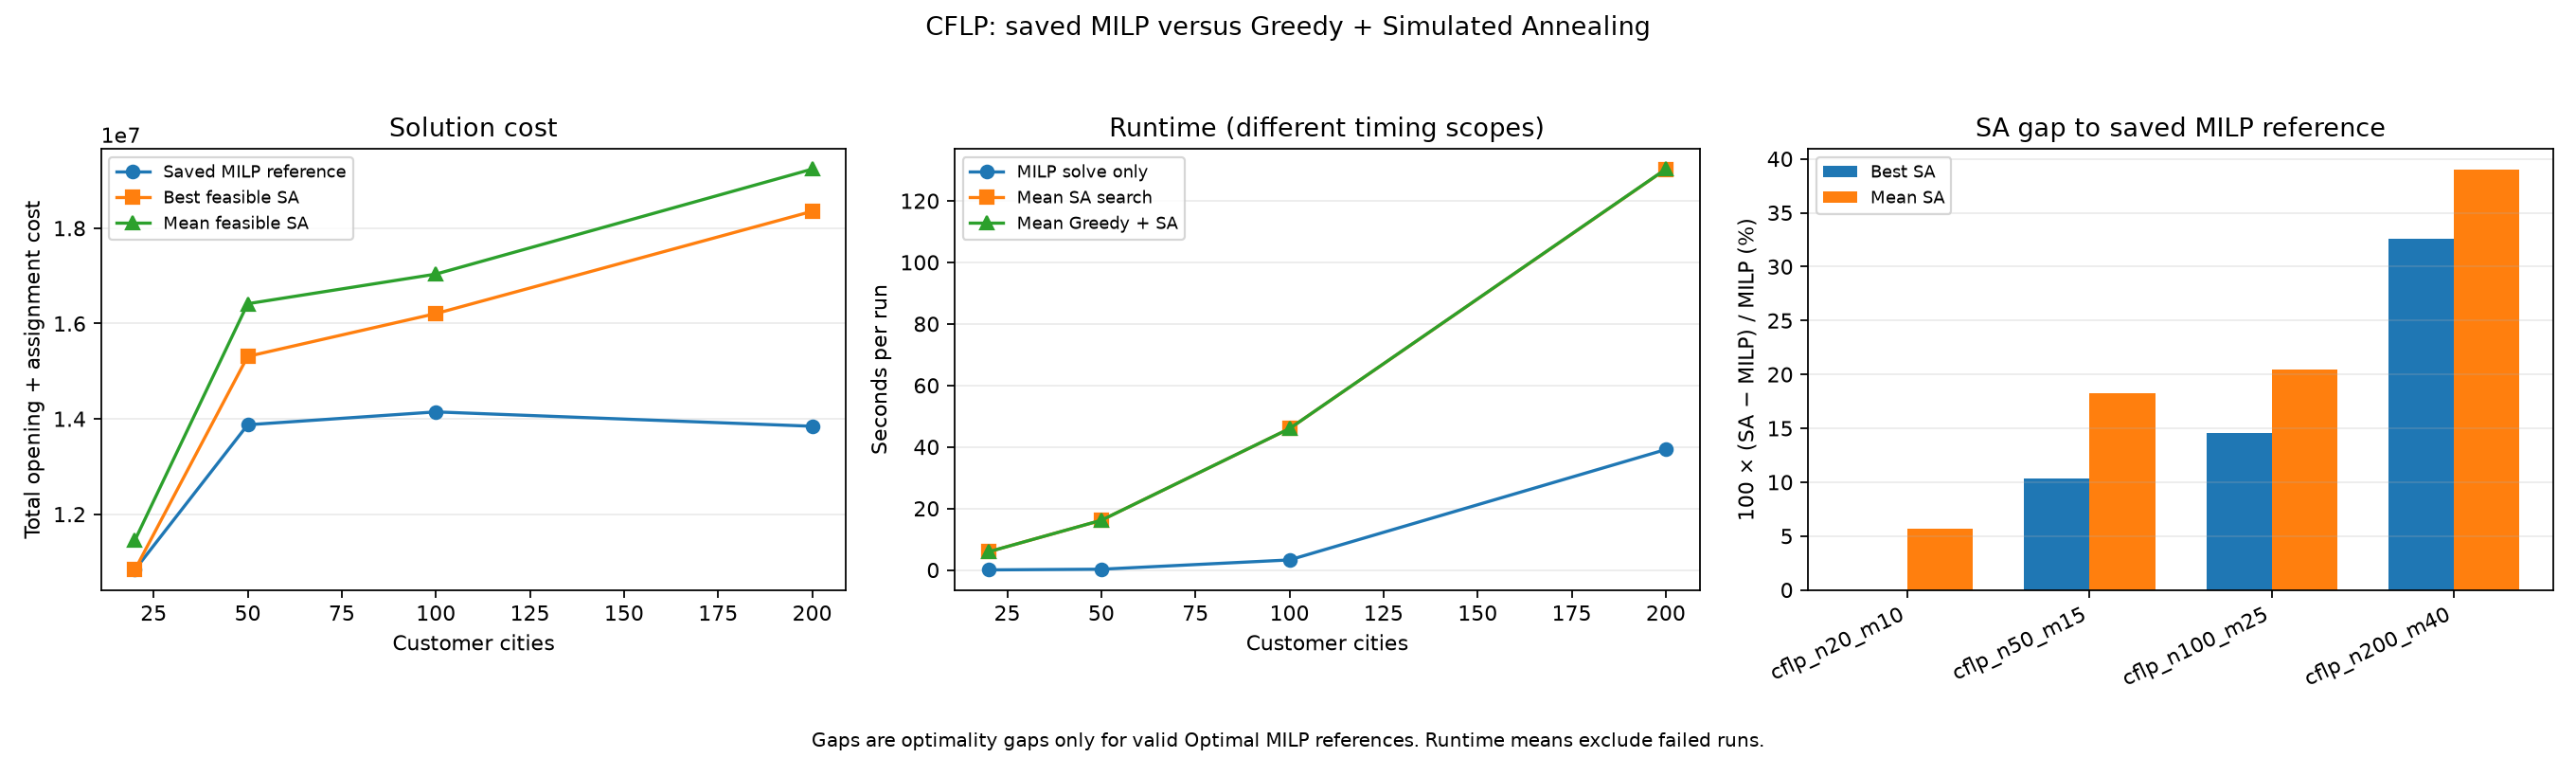

### Saved convergence across seeds

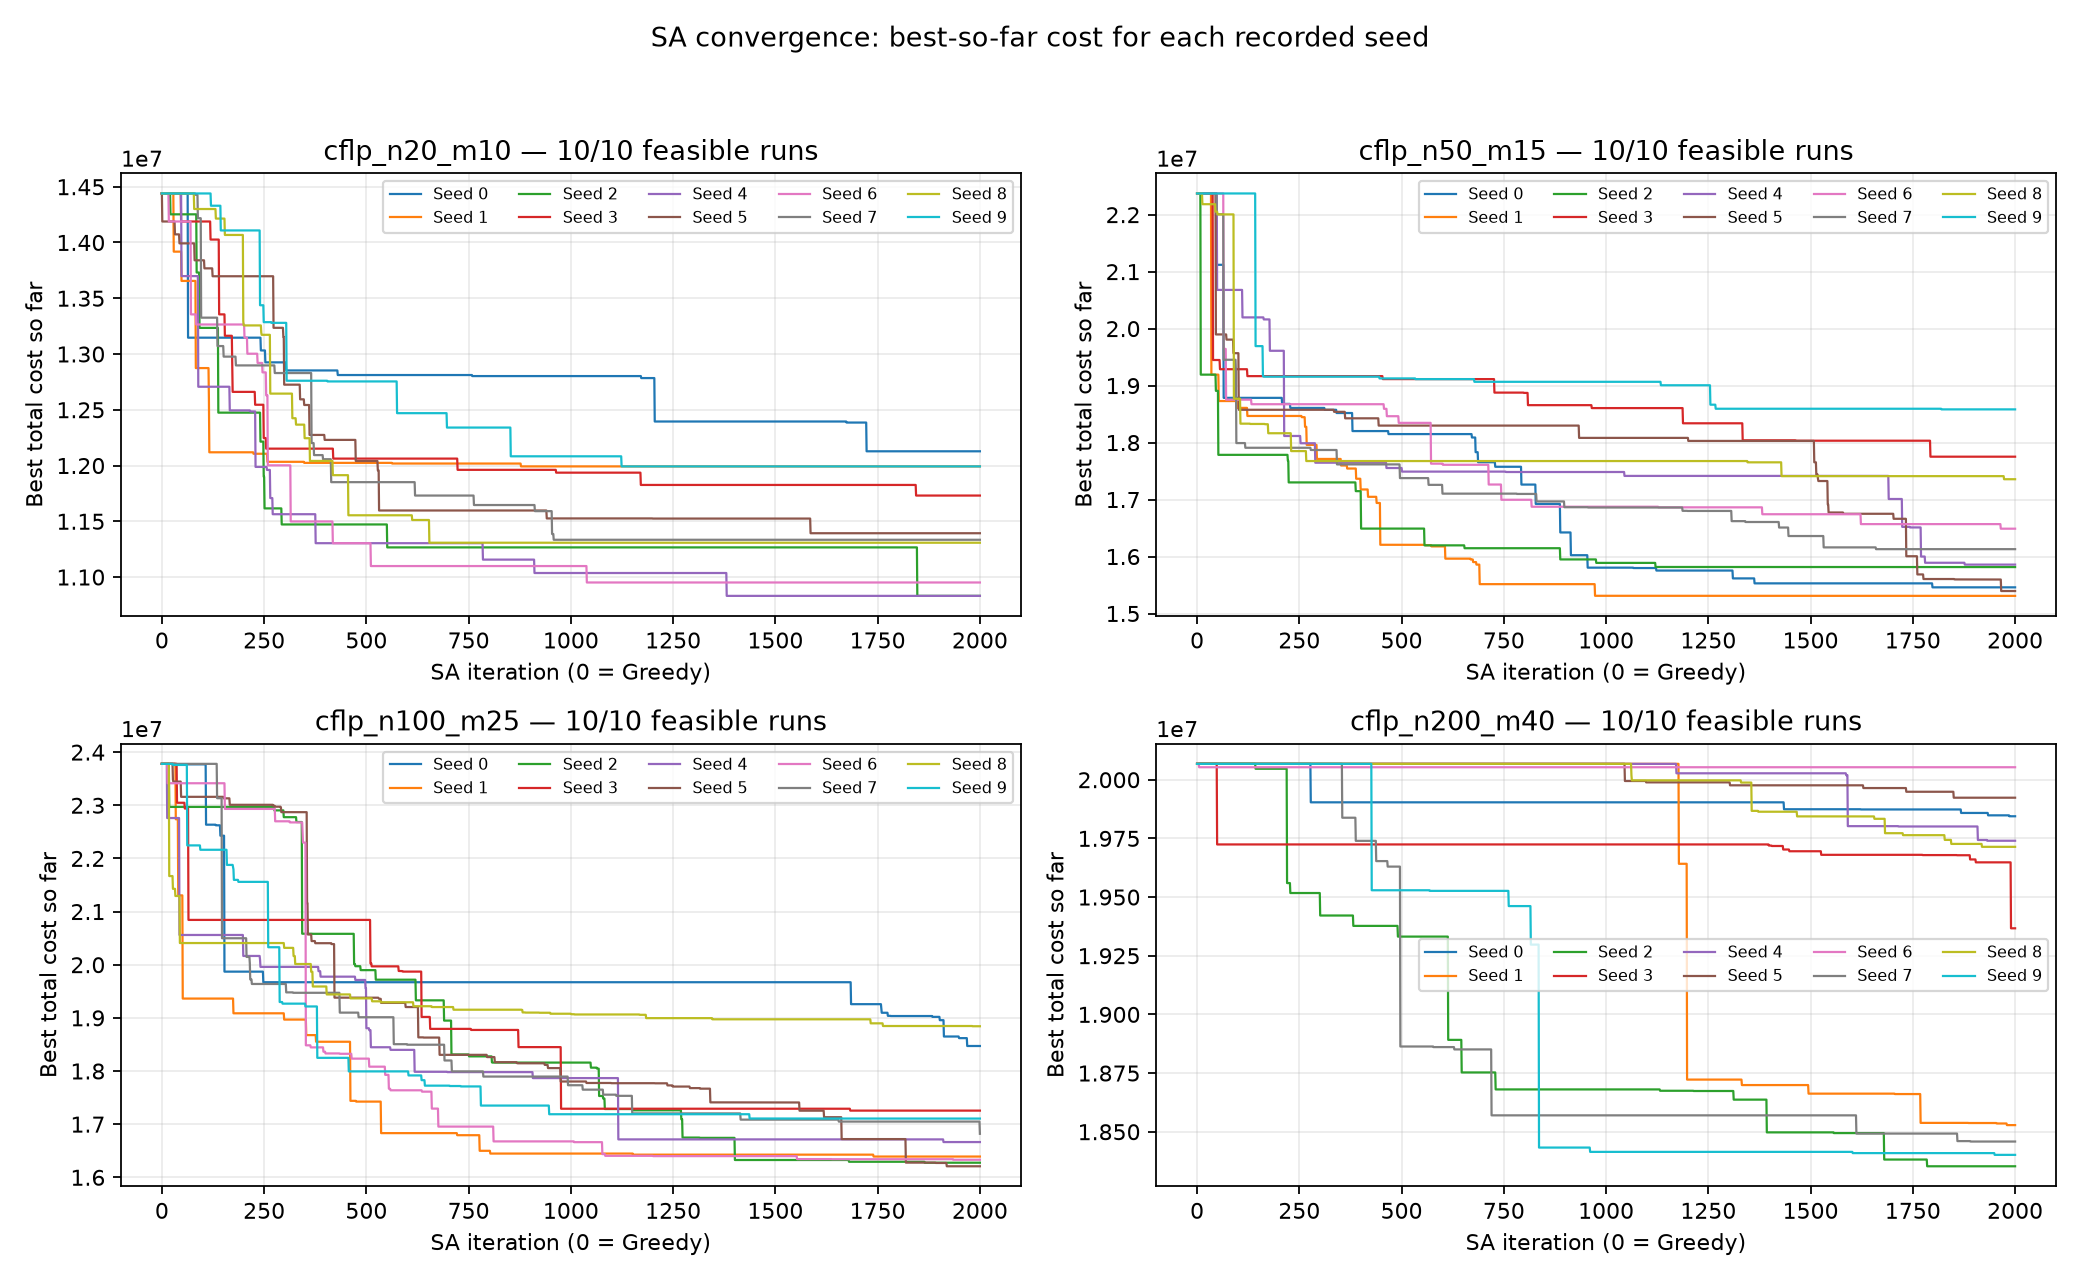

Saved convergence records: 80040


In [9]:
display(Markdown("### Solution quality, runtime and gap to MILP"))
display(Image(filename="data/heuristic_plots.png", width=1400))
display(Markdown("### Saved convergence across seeds"))
display(Image(filename="data/heuristic_convergence.png", width=1200))
with Path("data/sa_convergence.csv").open(encoding="utf-8") as handle:
    print("Saved convergence records:", sum(1 for _ in handle) - 1)

### Reading runtimes fairly
The saved MILP solver was faster on these instances. The readable SA implementation repeatedly validates full instance/assignment data, which adds Python overhead. MILP timing excludes model construction, while heuristic timing includes initialization plus search. Environment and timing-scope differences limit causal speed conclusions: this batch does not prove MILP is universally faster.

In [10]:
display(comparison_df[["instance", "milp_runtime_s", "mean_greedy_runtime_s",
                       "mean_sa_runtime_s", "mean_total_runtime_s"]].round(4))
print("Sum of recorded initialization/search times:",
      f"{sum(r['total_runtime_s'] for r in saved_payload['runs']) / 60:.2f} minutes")

,instance,milp_runtime_s,mean_greedy_runtime_s,mean_sa_runtime_s,mean_total_runtime_s
0,cflp_n20_m10,0.03,0.0014,5.9047,5.9061
1,cflp_n50_m15,0.25,0.0042,16.1568,16.1611
2,cflp_n100_m25,3.27,0.0144,45.9452,45.9597
3,cflp_n200_m40,39.15,0.0517,130.2549,130.3066


Sum of recorded initialization/search times: 33.06 minutes


## 10. Discussion
- **Smallest instance:** the best saved SA result for `n20_m10` matches the MILP optimum, 10,831,298.05. Two of ten experiment seeds attained it. This is not a guarantee for every seed.
- **Larger instances:** best gaps are **10.33%, 14.58%, 32.56%** for 50, 100, 200 customers. Relative quality deteriorated as size increased in this batch, although all 40 results were feasible.
- **Variability:** mean and sample standard deviation describe seed consistency. Reporting only the best hides weaker runs. The smallest instance's mean gap is 5.71% despite its zero best gap.
- **Fixed budget:** 2,000 attempts gives the same attempt count to different search-space sizes. Larger instances may need more attempts. Invalid and unchanged moves also consume iterations.
- **Neighborhood limits:** one random move can miss useful combinations. Greedy close/swap redistribution may fail when another relocation exists, restricting exploration.
- **Capacity:** cities are indivisible; sufficient total capacity alone does not guarantee feasible single-source packing. Overflow and fractional assignments are forbidden.
- **Objective consistency:** demand is already included in stored assignment costs, and opening cost is charged once per used facility.
- **Optimality:** SA returns candidates, not a proof of optimality. The saved Optimal MILP references provide the benchmark here.
- **Runtime:** MILP was faster in these saved experiments; timing scopes/environments prevent a universal method ranking.

## 11. Conclusion and future improvements
Greedy + SA is a reproducible and explainable feasible heuristic for Member A's single-source CFLP. It reached the smallest instance's saved optimum in the best runs; larger-instance gaps show room for improvement.

Future experiments should change one factor at a time, retain identical instances/seeds, and report feasibility, cost, variability and timing:

1. **Adaptive iteration budgets:** scale attempts with size; test documented stagnation/reheating rules.
2. **Better neighborhoods:** customer chains, multi-customer transfers and stronger capacity-aware close/swap repair.
3. **Parameter sensitivity:** systematically vary temperature/cooling, separating tuning and evaluation instances.
4. **Larger instances:** examine MILP time-limit cases; compare with valid incumbents/bounds without calling an unproven incumbent an optimum.
5. **Efficiency:** test reducing repeated static validation while preserving objective and feasibility semantics.

**Viva summary:** Greedy builds a feasible starting point. SA explores feasible alternatives and sometimes accepts worse current solutions. A separate best solution preserves progress. Interpret results with seed variability and benchmark status.

### Optional: explicitly rerun all experiments
**Leave disabled for a normal presentation or Run all.** To opt in, change `RERUN_ALL_EXPERIMENTS` to `True` and run the cell. It calls the existing runner with seeds 0–9 and the documented settings. The prior batch recorded about **33 minutes** of initialization/search time; Colab duration varies.

Outputs go to a new directory under `data/heuristic_reruns/`, preserving the original experiment baseline and Member A's files. The runner checkpoints complete runs and retains failure/interruption records. There is no automatic resume. If interrupted, disclose the completed count.

The cell also calls existing comparison/plot functions. The earlier presentation tables intentionally remain the original saved experiment; load the printed rerun directory to analyze a new batch.

In [11]:
RERUN_ALL_EXPERIMENTS = False  # Explicit opt-in; Run all skips this batch.
if RERUN_ALL_EXPERIMENTS:
    rerun_parent = Path("data/heuristic_reruns")
    rerun_parent.mkdir(parents=True, exist_ok=True)
    rerun_dir = Path(tempfile.mkdtemp(prefix="run_", dir=rerun_parent))
    rerun_records = run_experiments(Path("data/processed").glob("cflp_*.json"), rerun_dir,
                                   iterations=2000, cooling_rate=0.995,
                                   initial_temperature=None)
    rerun_summary = compare_results(read_csv("data/milp_results.csv"), rerun_records)
    write_csv(rerun_dir / "heuristic_comparison.csv", COMPARISON_FIELDS, rerun_summary)
    print_comparison(rerun_summary)
    create_plots(rerun_summary, read_csv(rerun_dir / "sa_convergence.csv"),
                 rerun_dir, rerun_records)
    rerun_meta = json.loads((rerun_dir / "heuristic_solutions.json").read_text())["metadata"]
    print("Rerun output directory:", rerun_dir)
    print("Recorded:", rerun_meta["recorded_runs"], "/", rerun_meta["expected_runs"],
          "| successful:", rerun_meta["successful_runs"],
          "| all attempted:", rerun_meta["all_runs_attempted"])
else:
    print("Skipped: using the saved 40-run experiment. No batch experiments were rerun.")

Skipped: using the saved 40-run experiment. No batch experiments were rerun.
